# Customer Data Cleaning

Cleaning, feature engineering and exploratory analysis on a marketing campaign customer dataset (2,240 rows, 29 columns).

## 1. Load and explore the data

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/marketing_campaign.csv", sep=";")
print(df.shape)
df.head()

(2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [6]:
df.isna().sum()[df.isna().sum() > 0]

,0
Income,24


In [7]:
print(df["Education"].value_counts(), "\n")
print(df["Marital_Status"].value_counts())

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64 

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


In [8]:
df_clean = df.copy()

## 2. Handle duplicates

In [9]:
print("Full duplicates:", df_clean.duplicated().sum())
print("Duplicates excluding ID:", df_clean.drop(columns="ID").duplicated().sum())

Full duplicates: 0
Duplicates excluding ID: 182


In [10]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=df_clean.columns.drop("ID"))
print("Rows removed:", before - len(df_clean))

Rows removed: 182


## 3. Fix categorical and date columns

In [11]:
df_clean["Marital_Status"] = df_clean["Marital_Status"].replace({"Alone": "Single"})
df_clean = df_clean[~df_clean["Marital_Status"].isin(["Absurd", "YOLO"])]
df_clean["Marital_Status"].value_counts()

,count
Marital_Status,
Married,795
Together,521
Single,451
Divorced,216
Widow,71


In [12]:
df_clean["Dt_Customer"] = pd.to_datetime(df_clean["Dt_Customer"])
df_clean["Dt_Customer"].dtype

dtype('<M8[ns]')

## 4. Outliers

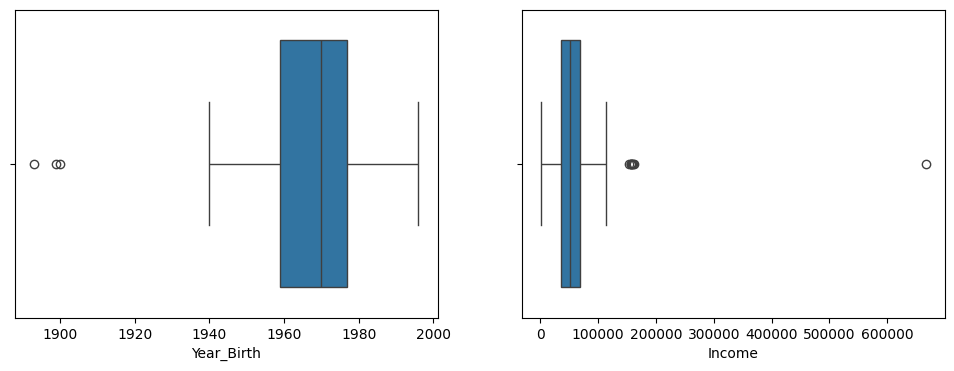

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df_clean["Year_Birth"], ax=axes[0])
sns.boxplot(x=df_clean["Income"], ax=axes[1])
plt.show()

In [14]:
before = len(df_clean)
df_clean = df_clean[df_clean["Year_Birth"] >= 1920]
df_clean = df_clean[(df_clean["Income"] < 200000) | (df_clean["Income"].isna())]
print("Rows removed:", before - len(df_clean))

Rows removed: 4


## 5. Missing values

In [15]:
print("Missing before:", df_clean["Income"].isna().sum())
df_clean["Income"] = df_clean["Income"].fillna(df_clean["Income"].median())
print("Missing after:", df_clean["Income"].isna().sum())

Missing before: 24
Missing after: 0


## 6. Drop constant columns

In [16]:
df_clean = df_clean.drop(columns=["Z_CostContact", "Z_Revenue"])

## 7. Feature engineering

In [17]:
current_year = df_clean["Dt_Customer"].dt.year.max()
df_clean["Age"] = current_year - df_clean["Year_Birth"]

mnt_cols = [c for c in df_clean.columns if c.startswith("Mnt")]
df_clean["Total_Spent"] = df_clean[mnt_cols].sum(axis=1)

num_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
df_clean["Total_Purchases"] = df_clean[num_cols].sum(axis=1)

df_clean["Total_Children"] = df_clean["Kidhome"] + df_clean["Teenhome"]
df_clean["Customer_Since_Days"] = (df_clean["Dt_Customer"].max() - df_clean["Dt_Customer"]).dt.days

df_clean[["Age", "Total_Spent", "Total_Purchases", "Total_Children", "Customer_Since_Days"]].head()

,Age,Total_Spent,Total_Purchases,Total_Children,Customer_Since_Days
0,57,1617,22,0,663
1,60,27,4,2,113
2,49,776,20,0,312
3,30,53,6,1,139
4,33,422,14,1,161


## 8. Final checks

In [18]:
print("Final shape:", df_clean.shape)
print("Missing values:", df_clean.isna().sum().sum())
print("Duplicates:", df_clean.duplicated().sum())
df_clean.describe().T

Final shape: (2050, 32)
Missing values: 0
Duplicates: 0


,count,mean,min,25%,50%,75%,max,std
ID,2050.0,5596.697561,0.0,2811.75,5511.0,8441.25,11191.0,3253.401646
Year_Birth,2050.0,1968.877561,1940.0,1959.0,1970.0,1977.0,1996.0,11.66329
Income,2050.0,52021.31561,1730.0,35685.0,51523.5,68146.5,162397.0,21475.110492
Kidhome,2050.0,0.446341,0.0,0.0,0.0,1.0,2.0,0.537785
Teenhome,2050.0,0.509756,0.0,0.0,0.0,1.0,2.0,0.546654
Dt_Customer,2050,2013-07-11 14:23:17.853658624,2012-07-30 00:00:00,2013-01-17 00:00:00,2013-07-12 00:00:00,2014-01-01 00:00:00,2014-06-29 00:00:00,NaN
Recency,2050.0,49.0,0.0,24.0,49.0,74.0,99.0,28.9857
MntWines,2050.0,304.062927,0.0,23.0,173.5,504.75,1493.0,336.8267
MntFruits,2050.0,26.171707,0.0,1.0,8.0,33.0,199.0,39.683358
MntMeatProducts,2050.0,167.716098,0.0,16.0,67.0,229.5,1725.0,228.353648


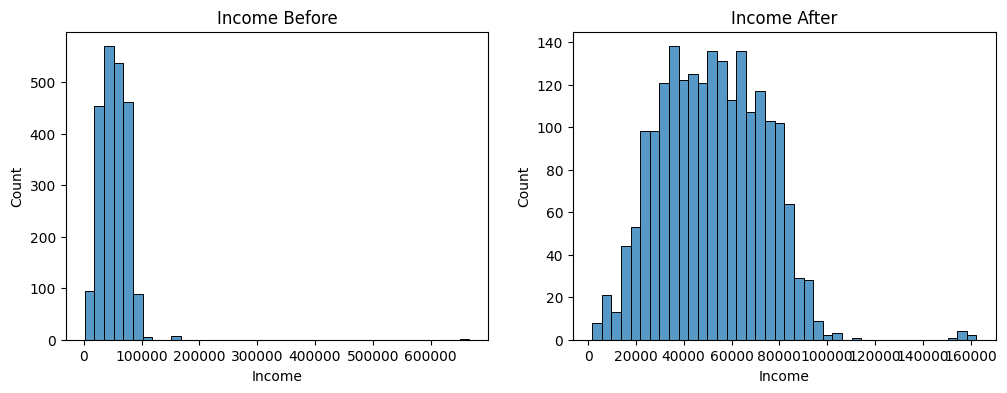

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Income"].dropna(), bins=40, ax=axes[0]).set_title("Income Before")
sns.histplot(df_clean["Income"], bins=40, ax=axes[1]).set_title("Income After")
plt.show()

## 9. Visualizations

In [20]:
os.makedirs("../images", exist_ok=True)

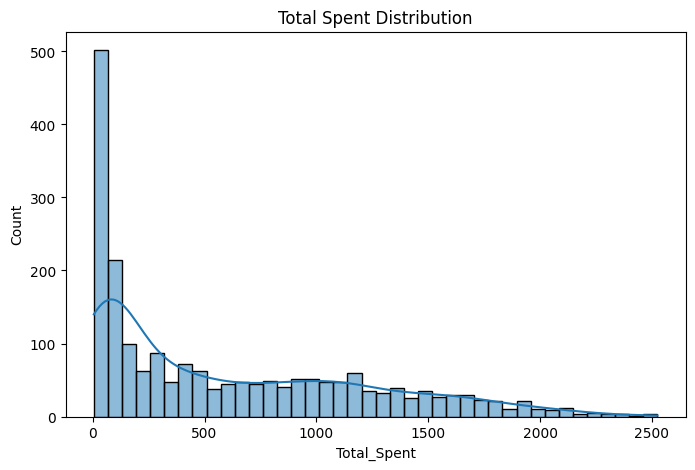

In [21]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["Total_Spent"], bins=40, kde=True)
plt.title("Total Spent Distribution")
plt.savefig("../images/total_spent_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

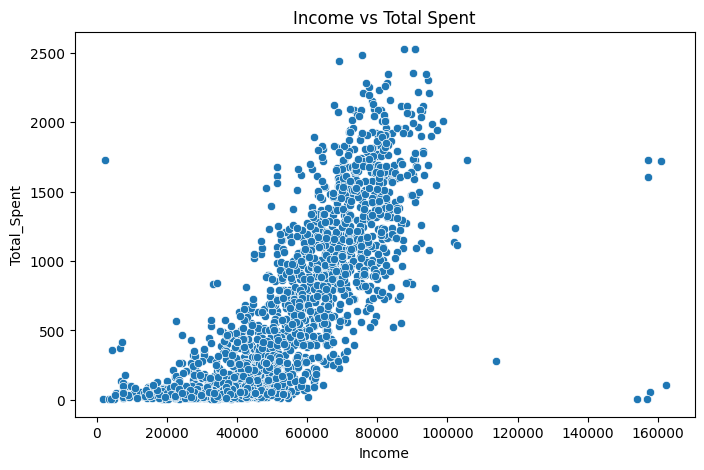

In [22]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x="Income", y="Total_Spent")
plt.title("Income vs Total Spent")
plt.savefig("../images/income_vs_spent.png", dpi=150, bbox_inches="tight")
plt.show()

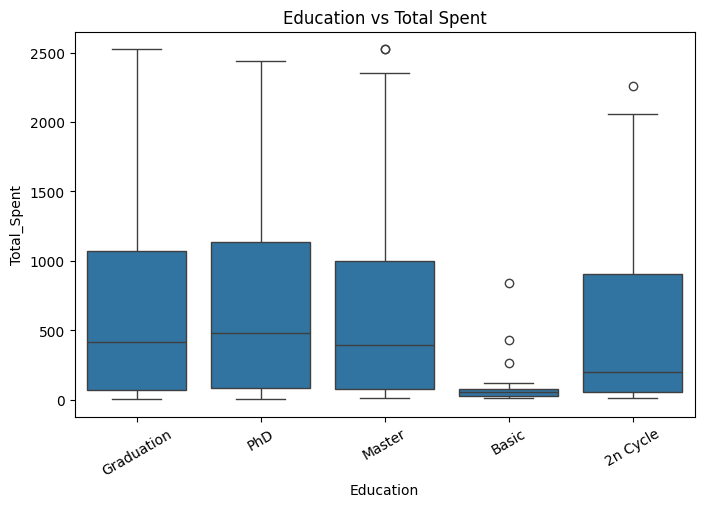

In [23]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="Education", y="Total_Spent")
plt.xticks(rotation=30)
plt.title("Education vs Total Spent")
plt.savefig("../images/education_vs_spent.png", dpi=150, bbox_inches="tight")
plt.show()

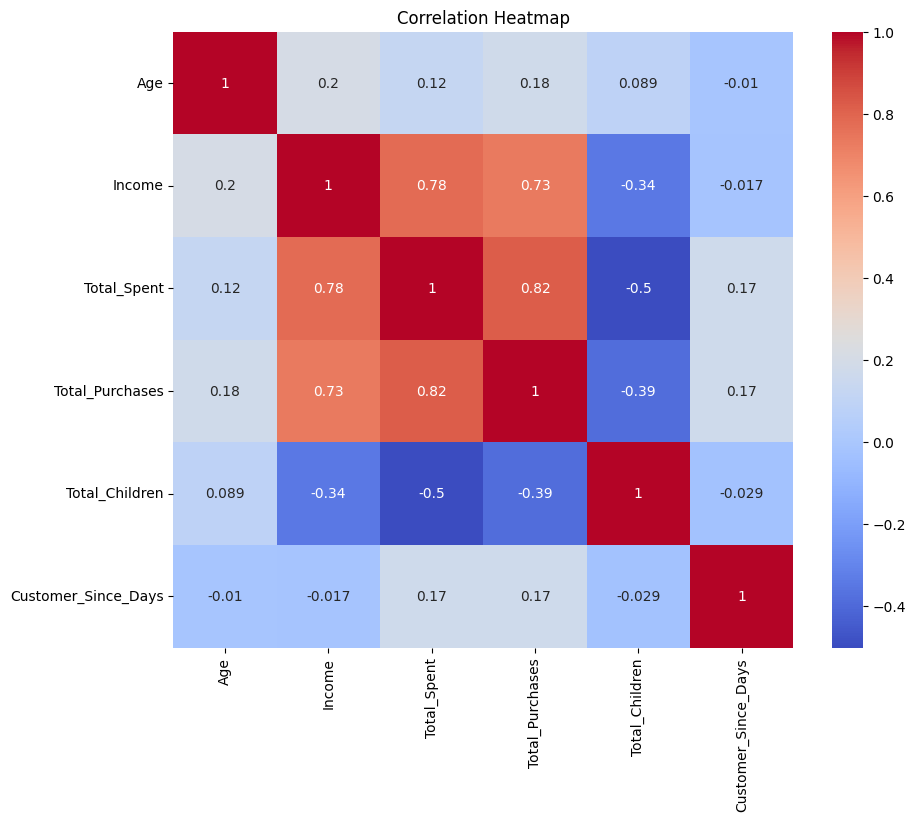

In [24]:
plt.figure(figsize=(10, 8))
corr_cols = ["Age", "Income", "Total_Spent", "Total_Purchases", "Total_Children", "Customer_Since_Days"]
sns.heatmap(df_clean[corr_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("../images/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Save cleaned data

In [ ]:
df_clean.to_csv("../data/processed/marketing_campaign_clean.csv", index=False)